# DARM (Liu et al. 2025): Panasonic 25C -> CMU eVTOL core-seven

This notebook runs `scripts/benchmarks/run_liu_cmu_darm.py`: the frozen Liu
et al. (2025) Panasonic 18650PF 25C source estimator (DARM: GRL adversarial
domain classification + reconstruction + adaptive multiscale MMD, target
BatchNorm running stats frozen) adapted independently to the CMU eVTOL
core-seven cells (three baseline protocol cells, four condition cells),
compared against a Source-only (no-adaptation) baseline. It follows the
same conventions as `33_bian_dtnn_panasonic25_to_cmu.ipynb` /
`34_backbone_transfer_panasonic_to_cmu.ipynb` /
`35_sftnn_med_transfer_panasonic_to_cmu.ipynb`: authenticated clone/pull
from GitHub, Drive-persisted paths from `configs/paths/colab_drive.yaml`,
per-cell checkpointing with `--resume` (now hash- and sidecar-verified
against the current CMU data version -- see the resume-safety diagnostics
below), and results read straight back off Drive.

Target adaptation missions are a duration-matched, chronological prefix of
each cell's Train-split missions, used WITHOUT SOC labels (source MSE +
adversarial + reconstruction + MMD only). Held-out Test-split missions are
scored only after adaptation, on the model's `last_step_per_window`
convention (each window's SOC prediction is the value at the window's LAST
row -- NOT DTNN/backbone's `all_timesteps` convention). A read-only,
no-grad diagnostic probe against the manifest's existing Validation-split
missions also runs every epoch (see the Diagnostics section) -- it never
participates in training, early stopping, or checkpoint selection. CMU
`soc_dynamic` is a development reference, not laboratory ground truth, so
every result row is `label_is_ground_truth=false` /
`formal_benchmark_eligible=false`, matching the rest of this repo's CMU
eVTOL benchmarks.

## 0. Clone/pull the repo (authenticated) and install

In [17]:
from pathlib import Path
import os, subprocess, sys, tempfile
from urllib.parse import urlunsplit

from google.colab import drive, userdata
drive.mount('/content/drive')

REPO = Path('/content/battery-soc-transfer-benchmark')
REPO_URL = urlunsplit(('https', 'github.com', '/zhangcastle/battery-soc-transfer-benchmark.git', '', ''))
github_token = userdata.get('GITHUB_TOKEN')
if not github_token:
    raise RuntimeError('Add the GITHUB_TOKEN Colab Secret and enable Notebook access')
if REPO.exists() and not (REPO / '.git').exists():
    raise RuntimeError(f'Remove incomplete checkout and rerun: {REPO}')
with tempfile.TemporaryDirectory() as temp_dir:
    askpass = Path(temp_dir) / 'git-askpass.sh'
    askpass.write_text('#!/bin/sh\ncase "$1" in\n*Username*) echo "x-access-token" ;;\n*) printf "%s" "$GITHUB_TOKEN" ;;\nesac\n')
    askpass.chmod(0o700)
    git_env = os.environ.copy()
    git_env.update({'GIT_ASKPASS': str(askpass), 'GIT_TERMINAL_PROMPT': '0', 'GITHUB_TOKEN': github_token})
    command = (['git', '-C', str(REPO), 'pull', '--ff-only'] if (REPO / '.git').exists() else ['git', 'clone', '--depth', '1', REPO_URL, str(REPO)])
    result = subprocess.run(command, env=git_env, text=True, capture_output=True)
del github_token
if result.returncode:
    raise RuntimeError('Authenticated GitHub setup failed; check token permission')
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', str(REPO)], check=True)
os.chdir(REPO)
src_path = str(REPO / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)
print('cwd:', Path.cwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cwd: /content/battery-soc-transfer-benchmark


## Paths (Drive-persisted input/output roots)

Same `configs/paths/colab_drive.yaml` the other CMU-transfer notebooks use.
`SOURCE_ARTIFACT` is the frozen source-domain checkpoint produced by
`20_liu_2025_darm_25c_to_0c.ipynb`'s formal Panasonic 25C run (never
retrained here) -- update the path below if your formal run used a
different output folder name.

In [18]:
import torch
from battery_benchmark.utils.config import load_yaml

PATHS = load_yaml(REPO / 'configs/paths/colab_drive.yaml')
PANASONIC_ROOT = Path(PATHS['raw_data_root']) / 'Panasonic_18650PF'
CMU_BASE_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel'
CMU_CONDITION_ROOT = REPO / 'outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel'
CMU_MANIFEST = REPO / 'data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv'
SOURCE_ARTIFACT = Path(PATHS['output_root']) / 'liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt'
RESULT_ROOT = Path(PATHS['output_root']) / (
    'benchmarks/panasonic_to_cmu_evtol/'
    'liu_2025_darm_ns_relabel_v2_e30_clean'
)

for path in (PANASONIC_ROOT, CMU_BASE_ROOT, CMU_CONDITION_ROOT, CMU_MANIFEST, SOURCE_ARTIFACT):
    assert path.exists(), f'Missing required input: {path}'

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)
print('source artifact:', SOURCE_ARTIFACT)
print('results (saved to Drive, survives a disconnect):', RESULT_ROOT)

device: cuda
source artifact: /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt
results (saved to Drive, survives a disconnect): /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/liu_2025_darm_ns_relabel_v2_e30_clean


## Before the full sweep: a smoke test

Run this once after a fresh clone/pull to catch a broken import or a bad
path before committing GPU time to the full sweep. Tiny epoch count, one
cell, writes to a throwaway local (non-Drive) output folder so it never
collides with -- or needs `--resume` protection from -- the real sweep
below.

In [19]:
smoke_root = Path('/content/darm_smoke_test')
subprocess.run(
    [
        sys.executable, '-u', str(REPO / 'scripts/benchmarks/run_liu_cmu_darm.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--source-artifact', str(SOURCE_ARTIFACT),
        '--output-root', str(smoke_root),
        '--cells', 'VAH01',
        '--epochs', '2',
        '--device', device,
    ],
    check=True,
)
print('smoke test passed')

smoke test passed


## Setup for the full sweep

`CELLS` defaults to all seven core cells. `--resume` is safe to re-run: the
script now (1) only skips a cell when `--resume` is passed AND a
`results.json` already exists, (2) verifies that cell's recorded
`cmu_input_sha256` against the freshly-hashed current CMU parquet, and (3)
verifies its `test_predictions.parquet`/`training_history.csv` sidecars are
still present -- a hash mismatch, a missing hash field, or a missing
sidecar all raise immediately rather than silently reusing a stale
result.

In [20]:
CELLS = ['VAH01', 'VAH17', 'VAH27', 'VAH30', 'VAH15', 'VAH12', 'VAH11']
EPOCHS = 30

def run_darm() -> None:
    command = [
        sys.executable, '-u', str(REPO / 'scripts/benchmarks/run_liu_cmu_darm.py'),
        '--panasonic-data-root', str(PANASONIC_ROOT),
        '--cmu-base-root', str(CMU_BASE_ROOT),
        '--cmu-condition-root', str(CMU_CONDITION_ROOT),
        '--cmu-manifest', str(CMU_MANIFEST),
        '--source-artifact', str(SOURCE_ARTIFACT),
        '--output-root', str(RESULT_ROOT),
        '--cells', *CELLS,
        '--epochs', str(EPOCHS),
        '--device', device,
        '--resume',
    ]
    print('Running:', ' '.join(command))
    subprocess.run(command, check=True)

## Run: Source only + DARM adaptation

With `--resume` and the per-cell checkpointing/result-hash verification in
the script, re-running this cell after a disconnect skips only the cells
that are both finished AND verified as coming from the current
`_ns_relabel` CMU data version.

In [21]:
run_darm()

Running: /usr/bin/python3 -u /content/battery-soc-transfer-benchmark/scripts/benchmarks/run_liu_cmu_darm.py --panasonic-data-root /content/drive/MyDrive/battery_soc_benchmark/data/raw/Panasonic_18650PF --cmu-base-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_ns_relabel --cmu-condition-root /content/battery-soc-transfer-benchmark/outputs/datasets/cmu_evtol/dynamic_capacity_soc_development_v1_extension4_ns_relabel --cmu-manifest /content/battery-soc-transfer-benchmark/data/manifests/cmu_evtol/cmu_evtol_supervised_budget_manifest_v0_1_ns_relabel.csv --source-artifact /content/drive/MyDrive/battery_soc_benchmark/outputs/liu_2025/25c_to_0c/formal_paper_protocol_v2_source_only/source_artifact.pt --output-root /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/liu_2025_darm_ns_relabel_v2_e30_clean --cells VAH01 VAH17 VAH27 VAH30 VAH15 VAH12 VAH11 --epochs 30 --device cuda --resume


## Results -- read straight from Drive

Reads `condition_metrics.csv` directly off Drive under `RESULT_ROOT` --
safe to re-run this section while a sweep above is still going or after a
partial run.

In [30]:
import pandas as pd
from IPython.display import display

condition_metrics_path = RESULT_ROOT / 'condition_metrics.csv'
condition_metrics = (
    pd.read_csv(condition_metrics_path) if condition_metrics_path.exists() else pd.DataFrame()
)
if not condition_metrics.empty:
    pivot = condition_metrics.pivot_table(
        index=['cell_id', 'condition'], columns='method',
        values=['overall_mae_percent', 'overall_rmse_percent'],
    ).round(3)
    display(pivot)

    rmse = condition_metrics.pivot_table(index='cell_id', columns='method', values='overall_rmse_percent')
    if {'Source only', 'DARM'} <= set(rmse.columns):
        display((rmse['DARM'] - rmse['Source only']).rename('DARM_minus_source_RMSE_points').round(3).to_frame())
    print('Metadata:', RESULT_ROOT / 'run_metadata.json')
else:
    print('No results yet under', RESULT_ROOT)

overall_mae_percent              \
method                                           DARM Source only   
cell_id condition                                                   
VAH01   baseline protocol                      43.659      42.116   
VAH11   20% lower discharge power              20.190      14.848   
VAH12   short 400 s cruise                     45.957      44.988   
VAH15   extended 1000 s cruise                 16.897      19.521   
VAH17   baseline protocol                      40.599      37.751   
VAH27   baseline protocol                      24.112      23.017   
VAH30   35 °C chamber                          40.329      52.607   

                                  overall_rmse_percent              
method                                            DARM Source only  
cell_id condition                                                   
VAH01   baseline protocol                       46.693      45.120  
VAH11   20% lower discharge power               25.151      21.656  
VAH12   short 400 s cruise                      49.227      48.852  
VAH15   extended 1000 s cruise                  20.862      23.556  
VAH17   baseline protocol                       43.691      40.858  
VAH27   baseline protocol                       26.735      27.258  
VAH30   35 °C chamber                           42.028      54.114

,DARM_minus_source_RMSE_points
cell_id,
VAH01,1.573
VAH11,3.495
VAH12,0.375
VAH15,-2.694
VAH17,2.834
VAH27,-0.523
VAH30,-12.085


Metadata: /content/drive/MyDrive/battery_soc_benchmark/outputs/benchmarks/panasonic_to_cmu_evtol/liu_2025_darm_ns_relabel_v2_e30_clean/run_metadata.json


## Diagnostics (Vidal/DTNN-alignment additions)

Everything below is read-only reporting on files `run_liu_cmu_darm.py`
already writes (`training_history.csv`, `test_predictions.parquet`,
`phase_metrics.csv`, `phase_transfer_effects.csv`, `run_metadata.json`) --
none of it changes what was trained or evaluated. It follows the same
`ns_raw`/`mission_phase`/phase-transfer-effects conventions as
`33_bian_dtnn_panasonic25_to_cmu.ipynb`'s diagnostics section; DARM's own
GRL/reconstruction/MMD/BatchNorm-freezing training and adaptation code is
untouched.

In [31]:
import json

training_history_path = RESULT_ROOT / 'training_history.csv'
test_predictions_path = RESULT_ROOT / 'test_predictions.parquet'
phase_metrics_path = RESULT_ROOT / 'phase_metrics.csv'
phase_transfer_effects_path = RESULT_ROOT / 'phase_transfer_effects.csv'
run_metadata_path = RESULT_ROOT / 'run_metadata.json'

training_history = (
    pd.read_csv(training_history_path) if training_history_path.exists() else pd.DataFrame()
)
test_predictions = (
    pd.read_parquet(test_predictions_path) if test_predictions_path.exists() else pd.DataFrame()
)
phase_metrics = pd.read_csv(phase_metrics_path) if phase_metrics_path.exists() else pd.DataFrame()
phase_transfer_effects = (
    pd.read_csv(phase_transfer_effects_path) if phase_transfer_effects_path.exists() else pd.DataFrame()
)
run_metadata = json.loads(run_metadata_path.read_text()) if run_metadata_path.exists() else {}

print('training_history rows:', len(training_history))
print('test_predictions rows:', len(test_predictions))
if run_metadata:
    print('evaluation_unit:', run_metadata.get('evaluation_unit'))
    print('phase_definition:', run_metadata.get('phase_definition'))
    print('target_validation_labels_used_for_diagnostics:', run_metadata.get('target_validation_labels_used_for_diagnostics'))
    print('target_validation_labels_used_for_training:', run_metadata.get('target_validation_labels_used_for_training'))
    print('target_validation_labels_used_for_checkpoint_selection:', run_metadata.get('target_validation_labels_used_for_checkpoint_selection'))
    print('git_commit:', run_metadata.get('git_commit'), 'git_dirty:', run_metadata.get('git_dirty'))

training_history rows: 210
test_predictions rows: 3355518
evaluation_unit: last_step_per_window
phase_definition: canonical Ns mapping: 4=take_off, 5=cruise, 6=landing
target_validation_labels_used_for_diagnostics: True
target_validation_labels_used_for_training: False
target_validation_labels_used_for_checkpoint_selection: False
git_commit: 61a644691379a84a912a0e3e8d4570f2d2babfd1 git_dirty: False


### Training / validation trajectory, domain accuracy, and BN/feature drift

`training_history.csv` has one row per (cell_id, epoch). `validation_mae`/
`validation_rmse` come from a read-only, no-grad probe against the
manifest's existing Validation-split missions (`validation_evaluated`
marks whether a cell actually had validation missions available) --
never used for training, early stopping, or checkpoint selection.
`runtime_seconds` is each epoch's real measured wall time. The plots below
average across cells for a single run so the shapes stay readable; group
`training_history` by `cell_id` directly for a per-cell breakdown.

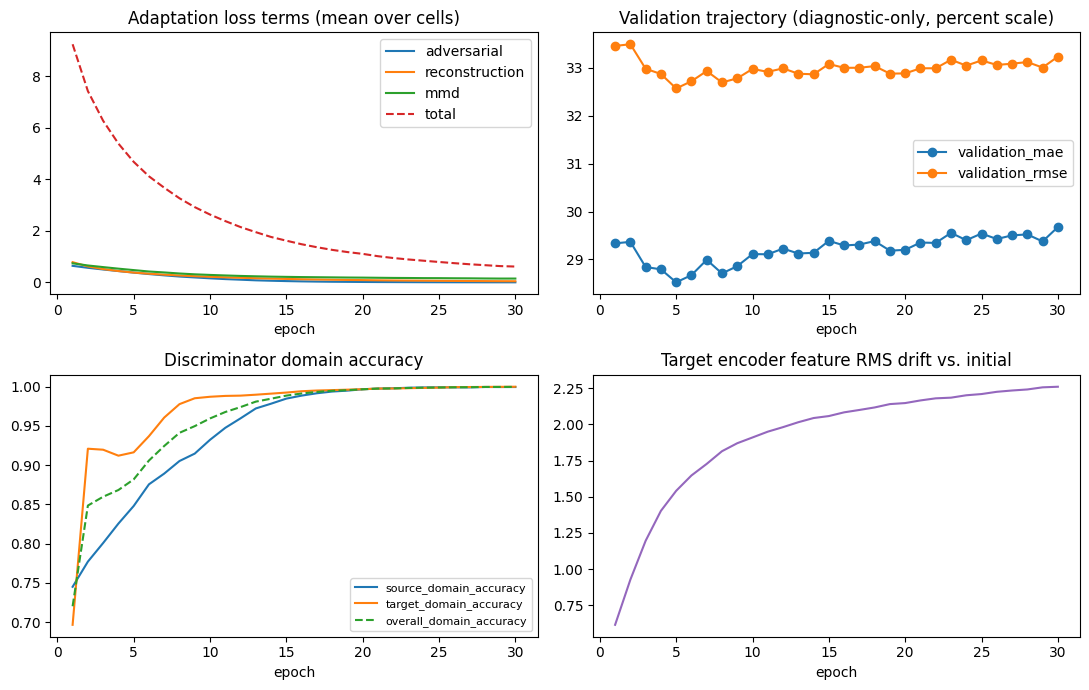

Total adaptation wall time by cell (s):


,runtime_seconds
cell_id,
VAH01,200.8
VAH11,455.4
VAH12,314.0
VAH15,177.0
VAH17,224.9
VAH27,161.0
VAH30,222.6


In [32]:
import matplotlib.pyplot as plt

if not training_history.empty:
    epoch_mean = training_history.groupby('epoch').mean(numeric_only=True)
    validation_rows = training_history.loc[training_history['validation_evaluated']]
    validation_mean = (
        validation_rows.groupby('epoch')[['validation_mae', 'validation_rmse']].mean()
        if not validation_rows.empty else pd.DataFrame()
    )

    fig, axes = plt.subplots(2, 2, figsize=(11, 7))

    axes[0, 0].plot(epoch_mean.index, epoch_mean['adversarial_loss'], label='adversarial')
    axes[0, 0].plot(epoch_mean.index, epoch_mean['reconstruction_loss'], label='reconstruction')
    axes[0, 0].plot(epoch_mean.index, epoch_mean['mmd_loss'], label='mmd')
    axes[0, 0].plot(epoch_mean.index, epoch_mean['total_loss'], label='total', linestyle='--')
    axes[0, 0].set_title('Adaptation loss terms (mean over cells)')
    axes[0, 0].set_xlabel('epoch'); axes[0, 0].legend()

    if not validation_mean.empty:
        axes[0, 1].plot(validation_mean.index, validation_mean['validation_mae'], marker='o', label='validation_mae')
        axes[0, 1].plot(validation_mean.index, validation_mean['validation_rmse'], marker='o', label='validation_rmse')
    axes[0, 1].set_title('Validation trajectory (diagnostic-only, percent scale)')
    axes[0, 1].set_xlabel('epoch'); axes[0, 1].legend()

    axes[1, 0].plot(epoch_mean.index, epoch_mean['source_domain_accuracy'], label='source_domain_accuracy')
    axes[1, 0].plot(epoch_mean.index, epoch_mean['target_domain_accuracy'], label='target_domain_accuracy')
    axes[1, 0].plot(epoch_mean.index, epoch_mean['overall_domain_accuracy'], label='overall_domain_accuracy', linestyle='--')
    axes[1, 0].set_title('Discriminator domain accuracy')
    axes[1, 0].set_xlabel('epoch'); axes[1, 0].legend(fontsize=8)

    axes[1, 1].plot(epoch_mean.index, epoch_mean['target_feature_rms_drift'], color='tab:purple')
    axes[1, 1].set_title('Target encoder feature RMS drift vs. initial')
    axes[1, 1].set_xlabel('epoch')

    fig.tight_layout()
    plt.show()

    runtime_by_cell = training_history.groupby('cell_id')['runtime_seconds'].sum().round(1)
    print('Total adaptation wall time by cell (s):')
    display(runtime_by_cell.to_frame())
else:
    print('No training_history.csv found at', training_history_path)

### Prediction-level diagnostics (`test_predictions.parquet`)

Per-window records (`framework, method, seed, cell_id, condition, split,
mission_cycle_id, window_index, timestep_index, mission_sequence_order,
elapsed_candidate_s, original_time_s, source_row_right, voltage_v_raw,
current_a_raw, temperature_c_raw, capacity_ah, capacity_source,
source_rpt_id, ns_raw, mission_phase, soc_reference, soc_prediction,
signed_error, absolute_error`), evaluated with DARM's own
`last_step_per_window` convention (`run_metadata['evaluation_unit']`) --
each row is one window's LAST-row prediction, not every timestep like
DTNN/backbone. `window_index` restarts at 0 for every mission.
`mission_phase` is derived from the raw, untouched `ns_raw` via the
canonical Ns mapping; flight-phase analysis below focuses on
`take_off`/`cruise`/`landing`.

,mean_abs_error_percent (last_step_per_window)
method,
DARM,32.834
Source only,32.167


method,DARM,Source only,adapted_minus_source
cell_id,,,
VAH01,43.659,42.116,1.543
VAH11,20.190,14.848,5.342
VAH12,45.957,44.988,0.969
VAH15,16.897,19.521,-2.625
VAH17,40.599,37.751,2.848
VAH27,24.112,23.017,1.095
VAH30,40.329,52.607,-12.278


Negative-transfer cells (adapted worse than source-only):


method,DARM,Source only,adapted_minus_source
cell_id,,,
VAH01,43.659,42.116,1.543
VAH11,20.190,14.848,5.342
VAH12,45.957,44.988,0.969
VAH17,40.599,37.751,2.848
VAH27,24.112,23.017,1.095


/tmp/ipykernel_7473/2482201596.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned = pred.groupby([bins, 'method'])['abs_error_percent'].mean().unstack('method')
/tmp/ipykernel_7473/2482201596.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned = pred.groupby([bins, 'method'])['abs_error_percent'].mean().unstack('method')


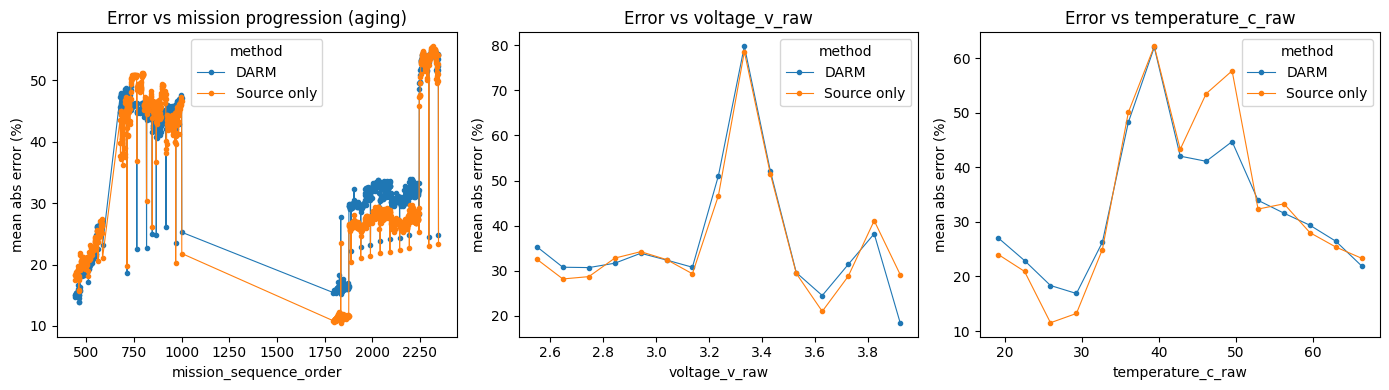

Worst 10 adapted-model missions by mean absolute error (%):


abs_error_percent
cell_id mission_cycle_id                                                     
VAH12   cmu_v3_dev_candidate_v0:VAH12:b6:s1309423:e1309484             55.041
        cmu_v3_dev_candidate_v0:VAH12:b6:s1307106:e1307167             55.034
        cmu_v3_dev_candidate_v0:VAH12:b6:s1306821:e1306882             54.895
        cmu_v3_dev_candidate_v0:VAH12:b6:s1307975:e1308036             54.878
        cmu_v3_dev_candidate_v0:VAH12:b6:s1312593:e1312654             54.856
        cmu_v3_dev_candidate_v0:VAH12:b6:s1308265:e1308326             54.855
        cmu_v3_dev_candidate_v0:VAH12:b6:s1308846:e1308907             54.825
        cmu_v3_dev_candidate_v0:VAH12:b6:s1309136:e1309197             54.771
        cmu_v3_dev_candidate_v0:VAH12:b6:s1308555:e1308616             54.768
        cmu_v3_dev_candidate_v0:VAH12:b6:s1312865:e1312926             54.757

In [33]:
if not test_predictions.empty:
    pred = test_predictions.copy()
    pred['abs_error_percent'] = pred['absolute_error'] * 100  # fraction -> percent for readability only

    overall_by_method = pred.groupby('method')['abs_error_percent'].mean().round(3)
    display(overall_by_method.rename('mean_abs_error_percent (last_step_per_window)').to_frame())

    per_cell_gain = (
        pred.groupby(['cell_id', 'method'])['abs_error_percent'].mean()
        .unstack('method')
    )
    if {'Source only', 'DARM'} <= set(per_cell_gain.columns):
        per_cell_gain['adapted_minus_source'] = (
            per_cell_gain['DARM'] - per_cell_gain['Source only']
        )
        display(per_cell_gain.round(3))
        negative_transfer_cells = per_cell_gain.loc[per_cell_gain['adapted_minus_source'] > 0]
        print('Negative-transfer cells (adapted worse than source-only):')
        display(negative_transfer_cells.round(3))

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    progression = (
        pred.groupby(['mission_sequence_order', 'method'])['abs_error_percent'].mean()
        .unstack('method')
    )
    progression.plot(ax=axes[0], marker='.', linewidth=0.8)
    axes[0].set_title('Error vs mission progression (aging)')
    axes[0].set_xlabel('mission_sequence_order'); axes[0].set_ylabel('mean abs error (%)')

    for column, ax_index in (('voltage_v_raw', 1), ('temperature_c_raw', 2)):
        bins = pd.cut(pred[column], bins=15)
        binned = pred.groupby([bins, 'method'])['abs_error_percent'].mean().unstack('method')
        binned.index = [interval.mid for interval in binned.index]
        binned.plot(ax=axes[ax_index], marker='.', linewidth=0.8)
        axes[ax_index].set_title(f'Error vs {column}')
        axes[ax_index].set_xlabel(column); axes[ax_index].set_ylabel('mean abs error (%)')

    fig.tight_layout()
    plt.show()

    adapted = pred.loc[pred['method'] == 'DARM']
    worst_missions = (
        adapted.groupby(['cell_id', 'mission_cycle_id'])['abs_error_percent']
        .mean().sort_values(ascending=False).head(10)
    )
    print('Worst 10 adapted-model missions by mean absolute error (%):')
    display(worst_missions.round(3).to_frame())
else:
    print('No test_predictions.parquet found at', test_predictions_path)

## Phase-level transfer effects (take_off / cruise / landing)

`phase_metrics.csv`/`phase_transfer_effects.csv` are read back directly
from `test_predictions.parquet` by the script (never re-derived from live
model state) -- same take_off/cruise/landing restriction and
`delta = DARM - Source only` convention as
`33_bian_dtnn_panasonic25_to_cmu.ipynb`'s full-mission phase diagnostic. A
positive delta means DARM adaptation made that (cell, condition,
mission_phase) worse than Source only, i.e. negative transfer.

In [26]:
if not phase_metrics.empty:
    display(
        phase_metrics.sort_values(['cell_id', 'method', 'mission_phase']).reset_index(drop=True)
    )
else:
    print('No phase_metrics.csv found at', phase_metrics_path)

,cell_id,condition,method,mission_phase,n_points,n_missions,mae_percent,rmse_percent,mean_signed_error_percent
0,VAH01,baseline protocol,DARM,cruise,161564,170,43.834809,46.784502,-43.834809
1,VAH01,baseline protocol,DARM,landing,17675,170,32.416226,32.559300,-32.416226
2,VAH01,baseline protocol,DARM,take_off,5976,166,72.154142,72.537553,-72.154142
3,VAH01,baseline protocol,Source only,cruise,161564,170,42.431891,45.322848,-42.431891
4,VAH01,baseline protocol,Source only,landing,17675,170,30.163253,30.313277,-30.163253
5,VAH01,baseline protocol,Source only,take_off,5976,166,68.927725,69.598009,-68.927725
6,VAH11,20% lower discharge power,DARM,cruise,417519,450,17.016312,19.830493,-17.016312
7,VAH11,20% lower discharge power,DARM,landing,46966,450,29.174855,31.031022,-29.174855
8,VAH11,20% lower discharge power,DARM,take_off,15876,441,77.087047,77.133036,-77.087047
9,VAH11,20% lower discharge power,Source only,cruise,417519,450,11.099964,14.788819,-11.099963


In [27]:
if not phase_transfer_effects.empty:
    display(
        phase_transfer_effects.sort_values(['cell_id', 'mission_phase']).reset_index(drop=True)
    )
    negative_transfer_summary = (
        phase_transfer_effects
        .groupby('mission_phase')[['negative_transfer_mae', 'negative_transfer_rmse']]
        .mean()
        .round(3)
    )
    print('Fraction of cells showing negative transfer, by phase:')
    display(negative_transfer_summary)
else:
    print('No phase_transfer_effects.csv found at', phase_transfer_effects_path)

,cell_id,condition,mission_phase,source_only_mae_percent,adapted_mae_percent,delta_mae_percent,source_only_rmse_percent,adapted_rmse_percent,delta_rmse_percent,negative_transfer_mae,negative_transfer_rmse
0,VAH01,baseline protocol,cruise,42.431891,43.834809,1.402918,45.322848,46.784502,1.461655,True,True
1,VAH01,baseline protocol,landing,30.163253,32.416226,2.252973,30.313277,32.559300,2.246022,True,True
2,VAH01,baseline protocol,take_off,68.927725,72.154142,3.226418,69.598009,72.537553,2.939544,True,True
3,VAH11,20% lower discharge power,cruise,11.099964,17.016312,5.916348,14.788819,19.830493,5.041674,True,True
4,VAH11,20% lower discharge power,landing,27.678351,29.174855,1.496504,30.381879,31.031022,0.649143,True,True
5,VAH11,20% lower discharge power,take_off,75.459068,77.087047,1.627979,75.547245,77.133036,1.585791,True,True
6,VAH12,short 400 s cruise,cruise,43.586899,44.869205,1.282306,47.376631,47.886183,0.509553,True,True
7,VAH12,short 400 s cruise,landing,39.469899,38.807033,-0.662867,39.965514,39.155568,-0.809945,False,False
8,VAH12,short 400 s cruise,take_off,82.974489,83.948797,0.974308,83.170274,84.089191,0.918918,True,True
9,VAH15,extended 1000 s cruise,cruise,18.422966,15.562538,-2.860428,22.505929,19.396808,-3.109121,False,False


Fraction of cells showing negative transfer, by phase:


,negative_transfer_mae,negative_transfer_rmse
mission_phase,,
cruise,0.714,0.571
landing,0.571,0.714
take_off,0.857,0.714
